Параметры ячейки для порядка 0: width = 17.64 | center = 0.00
Параметры ячейки для порядка 1: width = 4.98 | center = 38.47
Параметры ячейки для порядка 2: width = 4.10 | center = 54.41
Параметры ячейки для порядка 3: width = 3.74 | center = 66.63
Параметры ячейки для порядка 4: width = 3.43 | center = 76.94
Параметры ячейки для порядка 5: width = 3.23 | center = 86.02
Параметры ячейки для порядка 6: width = 3.11 | center = 94.23
Параметры ячейки для порядка 7: width = 2.99 | center = 101.78
Параметры ячейки для порядка 8: width = 2.86 | center = 108.81
Параметры ячейки для порядка 9: width = 2.76 | center = 115.41
Параметры ячейки для порядка 10: width = 2.68 | center = 121.66
Параметры ячейки для порядка 11: width = 2.62 | center = 127.59
Параметры ячейки для порядка 12: width = 2.57 | center = 133.27
Параметры ячейки для порядка 13: width = 2.50 | center = 138.71
Параметры ячейки для порядка 14: width = 2.46 | center = 143.94
Параметры ячейки для порядка 15: width = 2.40 | center = 

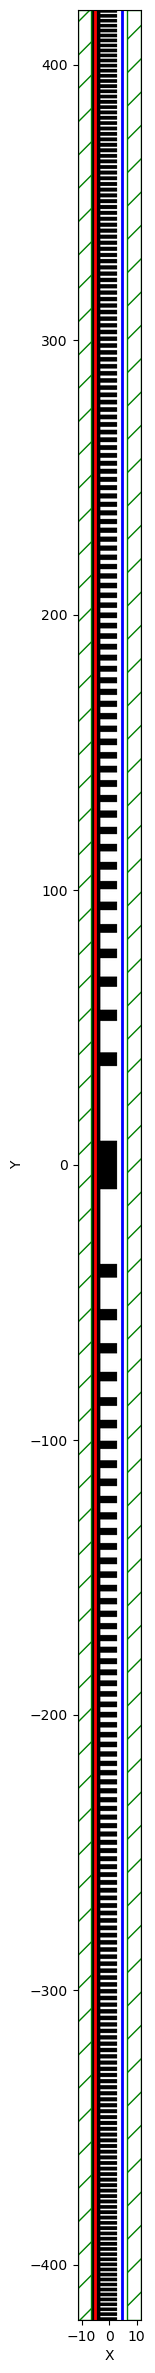

In [21]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Параметры симуляции для MEEP
resolution = 20  # разрешение сетки (точек на длину волны)
wavelength = 3.7  # длина волны источника
X_cell_size = conf.cell_X
Y_cell_size = 420*2
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X, side=mp.ALL)]
sources = [mp.Source(
    mp.GaussianSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(x=0, y=Y_cell_size),
)]

# Все параметры касающиеся определения геометрии
M = 120 # число радиальных слоёв.
N = 3 # число вертикальных повторений для каждого слоя.
k = 2 * np.pi / wavelength # волновое число
f = 200 # focal length 200 microns
spot_size = 400 
ff_res = 10 # far field resolution (points/μm)
Q = 300 # детализация
w = 0.5 # 500 nm (расстояние промежутка)
epsilon = 0.02  # Задайте точность, с которой y1 должен быть равен w

centers = []
width_curves = []
geometry = []
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center),
))
# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)


# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))
def zero_derivative (m):
    calculation = np.sqrt((4 * f * m * np.pi)/k)
    return calculation

# Main loop for layers
for m in range(M):
    center = zero_derivative(m)
    centers.append(center)
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m] - 0.01, Q)
    # Compute y values by integration
    y = np.array([quad(fun, rt0, xi)[0] for xi in x])
    xt = x.copy()
    ip = np.argmin(y)
    y1 = y - y[ip]

    # Найти первое значение x, при котором y1 примерно равно w
    index = np.argmax(np.abs(y1 - w) < epsilon)
    if np.abs(y1[index] - w) < epsilon:
        x_first_close_to_w = x[index]
    else:
        raise ValueError(f"Для слоя {m} значение x, соответствующее y1 ≈ {w}, не найдено. Увеличь Q!")

    dx = abs(2*(center - x[index]))
    width_curves.append(dx)

    print(f'Параметры ячейки для порядка {m}: width = {dx:.2f} | center = {center:.2f}')

# Зальем теперь это все в геометрию
for m in range(M):
    geometry.append(mp.Block(
        material=conf.in_material,
        size=mp.Vector3(conf.at_hei, width_curves[m], 0),
        center=mp.Vector3(x=conf.at_center, y=centers[m], z=0)
    ))

    geometry.append(mp.Block(
        material=conf.in_material,
        size=mp.Vector3(conf.at_hei, width_curves[m], 0),
        center=mp.Vector3(x=conf.at_center, y=-centers[m], z=0)
    ))

sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=resolution,
    split_chunks_evenly=False
)


# Добавление near2far области
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    0,      # ширина спектра
    1,
    mp.Near2FarRegion(direction=mp.Y,center=conf.flux_center, size=mp.Vector3(y=Y_cell_size)),
)

plt.figure(figsize=(5, 30))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0], cell[1],0))
)
plt.savefig("precomp_near_plot.png", dpi = 100)  # Сохранение изображения в файл
plt.show()  # Отображение изображения

In [22]:
# Запуск симуляции
sim.run(until_after_sources=100)

# Вычисление полей в дальней зоне
far_field = sim.get_farfields(
    near2far_region,
    ff_res,
    center=mp.Vector3(x=conf.flux_center[0] + f),
    size = mp.Vector3(spot_size)
)

-----------
Initializing structure...
time for choose_chunkdivision = 0.000577927 s
Working in 2D dimensions.
Computational cell is 23 x 840 x 0 with resolution 20
     block, center = (-5,0,0)
          size (3,1e+20,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,0,0)
          size (6,17.6436,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,-0,0)
          size (6,17.6436,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,38.4708,0)
          size (6,4.98237,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (11.56,11.56,11.56)
     block, center = (-0.5,-38.4708,0)
          size (6,4.98237,0)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon di

FloatProgress(value=0.0, description='0% done ', max=470.0)

Meep progress: 2.4250000000000003/470.0 = 0.5% done in 4.0s, 773.0s to go
on time step 97 (time=2.425), 0.0412859 s/step
Meep progress: 4.75/470.0 = 1.0% done in 8.0s, 785.2s to go
on time step 190 (time=4.75), 0.0430848 s/step
Meep progress: 7.3500000000000005/470.0 = 1.6% done in 12.0s, 757.2s to go
on time step 294 (time=7.35), 0.0385885 s/step
Meep progress: 8.525/470.0 = 1.8% done in 17.4s, 943.3s to go
on time step 341 (time=8.525), 0.114787 s/step
Meep progress: 11.125/470.0 = 2.4% done in 21.5s, 885.1s to go
on time step 445 (time=11.125), 0.0387725 s/step
Meep progress: 13.725000000000001/470.0 = 2.9% done in 25.5s, 847.6s to go
on time step 549 (time=13.725), 0.0388146 s/step
Meep progress: 16.3/470.0 = 3.5% done in 29.5s, 821.4s to go
on time step 652 (time=16.3), 0.0389675 s/step
Meep progress: 18.875/470.0 = 4.0% done in 33.5s, 801.0s to go
on time step 755 (time=18.875), 0.038878 s/step
Meep progress: 21.475/470.0 = 4.6% done in 37.5s, 783.6s to go
on time step 859 (time=

In [23]:
Ez_far_field = far_field["Ez"]

In [24]:
Ez_far_field[1000]

(4.37689367713788e-15+1.8337809298395874e-13j)

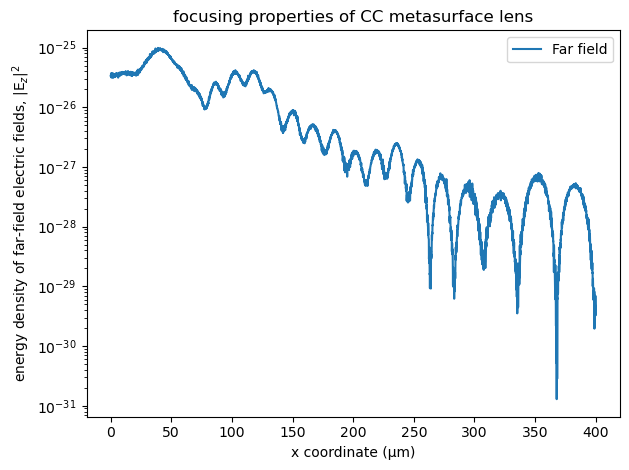

In [25]:
x = np.linspace(
    f -0.5 * spot_size,
    f + 0.5 * spot_size,
    ff_res * spot_size,
)

plt.figure(dpi=100)
plt.semilogy(
    x, abs(Ez_far_field)**2, label="Far field"
)
plt.xlabel("x coordinate (μm)")
plt.ylabel(r"energy density of far-field electric fields, |E$_z$|$^2$")
plt.title("focusing properties of CC metasurface lens")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [26]:
x

array([0.00000000e+00, 1.00025006e-01, 2.00050013e-01, ...,
       3.99799950e+02, 3.99899975e+02, 4.00000000e+02])